# EN3150 Assignment 03- NEXORA

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [71]:
# image sizes
image_height = 64
image_width = 64

#this will use later during training
batch_size = 32
epochs = 20

print("Image size:", image_height, "x", image_width)

Image size: 64 x 64


In [72]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("Seed set to", seed)

Seed set to 42


## Data Preparation


In [73]:
import os
from sklearn.model_selection import train_test_split

### Loading the RealWaste dataset

In [74]:
# downloading the RealWaste dataset from UCI
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

realwaste.zip           [        <=>         ] 656.65M  61.2MB/s    in 12s     


In [75]:
# extracting the dataset
!unzip -oq realwaste.zip -d realwaste_data

In [76]:
# extracted files
print(os.listdir("realwaste_data"))

['realwaste-main']


In [77]:
dataset_path = "realwaste_data/realwaste-main/RealWaste"

print(os.listdir(dataset_path))

['Plastic', 'Miscellaneous Trash', 'Vegetation', 'Food Organics', 'Textile Trash', 'Metal', 'Cardboard', 'Glass', 'Paper']


In [78]:
# get class names
class_names = os.listdir(dataset_path)
class_names.sort()

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


In [79]:
# count images in each class
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))

    print(class_name, ":", image_count)
    total_images = total_images + image_count

print("Total images:", total_images)

Cardboard : 461
Food Organics : 411
Glass : 420
Metal : 790
Miscellaneous Trash : 495
Paper : 500
Plastic : 921
Textile Trash : 318
Vegetation : 436
Total images: 4752


### Sample images

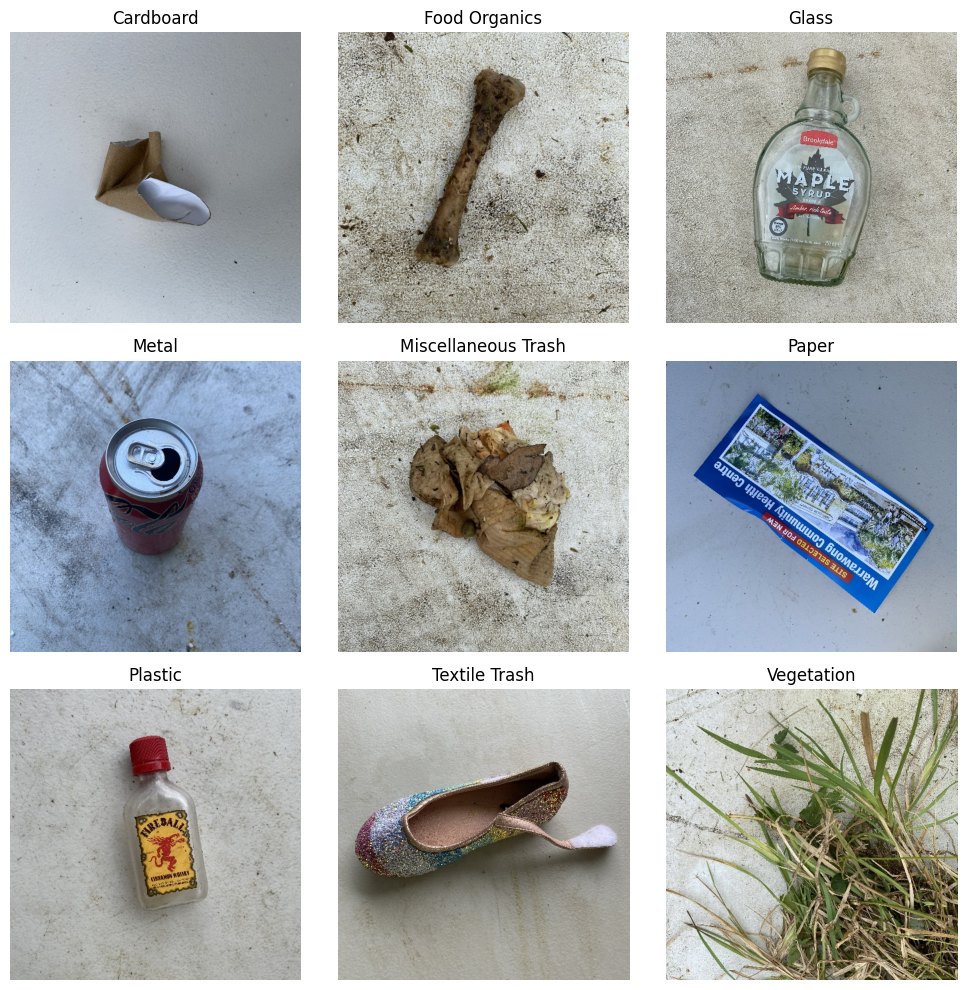

In [80]:
# show one image from each class
plt.figure(figsize=(10, 10))

for i in range(len(class_names)):
    class_name = class_names[i]
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_name = image_files[0]

    image_path = os.path.join(class_path, image_name)
    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Image paths and labels

In [81]:
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_files.sort()

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_number)

print("Images:", len(image_paths))
print("Labels:", len(labels))

Images: 4752
Labels: 4752


### Train, validation and test split

In [82]:
# keep 70% for training
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

In [83]:
# divide the remaining 30% equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=seed,
    stratify=temp_labels
)

In [84]:
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 3326
Validation images: 713
Testing images: 713


In [85]:
print("Training:", round(len(train_paths) / total_images * 100, 2), "%")
print("Validation:", round(len(val_paths) / total_images * 100, 2), "%")
print("Testing:", round(len(test_paths) / total_images * 100, 2), "%")

Training: 69.99 %
Validation: 15.0 %
Testing: 15.0 %


### Image preprocessing

In [86]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(
        image,
        [image_height, image_width]
    )

    image = tf.cast(image, tf.float32)
    image = image / 255.0

    return image, label

In [87]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(load_image)

train_ds = train_ds.shuffle(
    len(train_paths),
    seed=seed
)

train_ds = train_ds.batch(batch_size)

In [88]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(batch_size)

In [89]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(load_image)
test_ds = test_ds.batch(batch_size)

In [90]:
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


In [91]:
for images, batch_labels in train_ds.take(1):
    print("Minimum value:", tf.reduce_min(images).numpy())
    print("Maximum value:", tf.reduce_max(images).numpy())

Minimum value: 0.0
Maximum value: 1.0


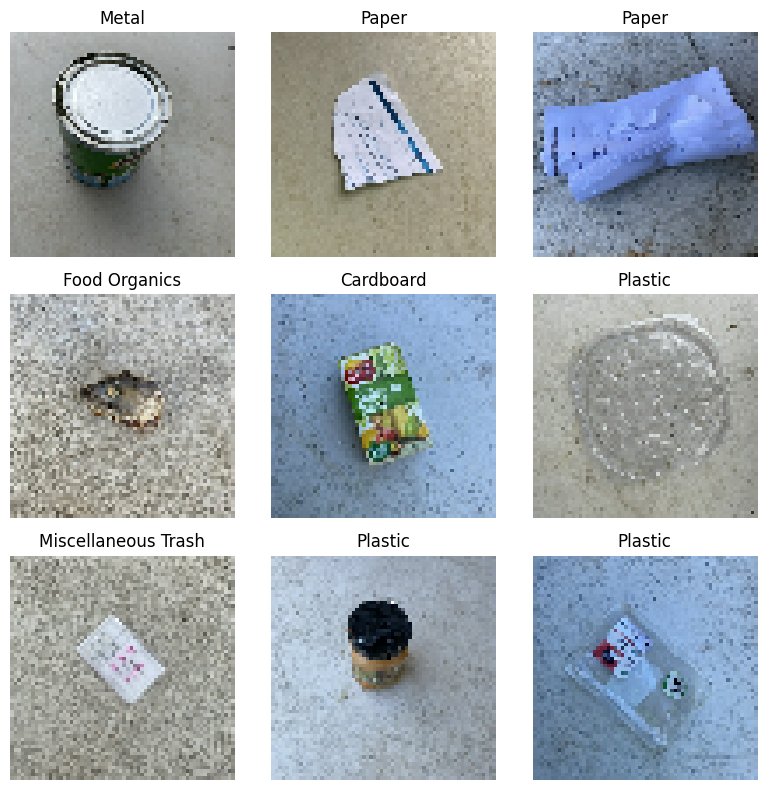

In [92]:
for images, batch_labels in train_ds.take(1):

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[batch_labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Optimizer Selection and Training

In [103]:

# Optimizers that will be compared
learning_rate = 0.001

def make_optimizer(name):
    if name == "sgd":
        return keras.optimizers.SGD(
            learning_rate=learning_rate
        )

    if name == "momentum":
        return keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    if name == "adam":
        return keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    raise ValueError(f"Unknown optimizer: {name}")

print("SGD optimizer prepared")
print("SGD with Momentum optimizer prepared")
print("Adam selected as the main optimizer")

SGD optimizer prepared
SGD with Momentum optimizer prepared
Adam selected as the main optimizer


In [94]:
def train_model(model, optimizer, epochs=20):

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        verbose=1
    )

    end_time = time.time()

    training_time = end_time - start_time

    return history, training_time

Add Exact model A architecture

In [104]:

def build_model_a():
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(
            16, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])

    return model




In [105]:
temp_a = build_model_a()
print("Model A parameters:", temp_a.count_params())

Model A parameters: 286377


Add exact Model B architecture


In [106]:

def ds_block(x, filters, pool=True):
    x = layers.DepthwiseConv2D(
        (3, 3),
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)

    x = layers.Conv2D(
        filters,
        (1, 1),
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)

    if pool:
        x = layers.MaxPooling2D((2, 2))(x)

    return x


def build_model_b():
    inputs = keras.Input(shape=(64, 64, 3))

    x = layers.Conv2D(
        16, (3, 3),
        padding="same",
        use_bias=False
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = ds_block(x, 32, pool=True)
    x = ds_block(x, 64, pool=True)
    x = ds_block(x, 128, pool=True)
    x = ds_block(x, 256, pool=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64)(x)
    x = layers.ReLU(max_value=6.0)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return keras.Model(inputs, outputs)


In [107]:
temp_b = build_model_b()

trainable_b = sum(
    np.prod(w.shape)
    for w in temp_b.trainable_weights
)

print("Model B trainable parameters:", trainable_b)

Model B trainable parameters: 64617


##Loss curve code


In [95]:
def plot_loss_curves(history, title):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [96]:
def plot_accuracy_curves(history, title):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

##Evaluation code

In [97]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

def evaluate_model(model):

    y_true = []
    y_pred = []

    for images, labels in test_ds:

        predictions = model.predict(
            images,
            verbose=0
        )

        predicted_labels = np.argmax(
            predictions,
            axis=1
        )

        y_true.extend(labels.numpy())
        y_pred.extend(predicted_labels)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return y_true, y_pred, accuracy, precision, recall

##Confusion Matrix

In [98]:
import seaborn as sns

def plot_confusion_matrix(y_true, y_pred, title):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

##Results

In [99]:
def print_results(
    accuracy,
    precision,
    recall,
    training_time
):

    print("Test Accuracy :", f"{accuracy:.4f}")
    print("Precision     :", f"{precision:.4f}")
    print("Recall        :", f"{recall:.4f}")
    print("Training Time :", f"{training_time:.2f} seconds")


In [101]:

num_classes = len(class_names)

print("Number of classes:", num_classes)


Number of classes: 9


In [102]:
print("Training dataset:", train_ds)
print("Validation dataset:", val_ds)
print("Test dataset:", test_ds)
print("Classes:", class_names)
print("Number of classes:", num_classes)

Training dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Validation dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Test dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9
